# 🔍 EDA — 학습 전에 했어야 할 데이터 탐색

### 지금까지의 이야기

- 알람 웹앱: 사용자가 스캔 틀 안에 **물건 하나를, 크게, 가운데에** 비추면 알람이 꺼진다.
- 모델: `yolo11n`(COCO)을 Open Images 10종으로 파인튜닝했다.
  마우스 · 우산 · 책 · 칫솔은 COCO가 원래 알던 것, 모자 · 문 · 휴지 · 양말 · 신발 · 안경은 새로 가르친 것.
- 실험 A(전체 미세조정)와 B(백본 고정)는 **같은 데이터**로 학습했고, 둘 다 val mAP50 **0.61~0.63** 근처에서 멈췄다.
  학습 방식을 바꿔도 천장이 같다면 → **데이터를 의심**해야 한다.

실험 A의 클래스별 val mAP50 (`wakeup_mission.ipynb` 결과):

| 마우스 | 칫솔 | 휴지 | 안경 | 모자 | 우산 | 양말 | 신발 | 문 | 책 |
|---|---|---|---|---|---|---|---|---|---|
| .87 | .85 | .82 | .75 | .71 | .70 | .51 | .42 | .36 | .33 |

우리는 데이터를 제대로 살펴보지 않고 바로 학습했다. **이 노트북이 원래 맨 먼저 했어야 할 EDA**다.
여기서 찾은 것으로 A · B의 천장을 설명하고, 실험 C(데이터 청소, `wakeup_clean.ipynb`)의 규칙을 정한다.

### 계속 던질 질문: "학습 데이터가 앱이 보는 장면과 닮았나?"

| 단계 | 내용 |
|---|---|
| 0 | 설정 + 박스 표 만들기 |
| 1 | 데이터 한눈에 (사진 · 박스 수, val이 믿을 만한가) |
| 2 | 박스 크기 |
| 3 | 사진당 박스 수 |
| 4 | 속성 (묶음 · 그림 · 가림 · 잘림 · 안쪽) |
| 5 | 위치 히트맵 (가운데에 있나) |
| 6 | 가로세로 비율 |
| 7 | 같이 나오는 클래스 |
| 8 | 사진 해상도 |
| 9 | 클래스별 사진 모아 보기 (문 · 책 · 신발) |
| 10 | 발견 정리 → 청소 규칙 |
| 11 | 청소 후 다시 보기 (전/후) |

## 0. 설정

데이터는 `wakeup_mission.ipynb`가 FiftyOne에 받아 둔 Open Images를 **읽기만** 한다 (학습 · 내보내기 없음, GPU 필요 없음).

박스 하나 = 한 줄인 **표(DataFrame) 하나**를 만들고, 이후 모든 그림은 이 표에서 그린다.
표를 만드는 함수는 `src/eda.py`의 `box_table`이다 (테스트: `tests/test_eda.py`).

| 열 | 뜻 |
|---|---|
| `x, y, w, h` | 박스 (사진 크기로 나눈 0~1 값, 왼쪽 위 기준) |
| `area` | `w*h` = 사진 면적 대비 박스 면적 |
| `aspect` | 픽셀 기준 가로/세로 (1보다 크면 옆으로 넓음) |
| `cx, cy` | 박스 중심 |
| `IsGroupOf` 등 | Open Images 속성 (없으면 False) |
| `drop` | 실험 C 청소 규칙에 걸리나 (묶음 · 그림 · 면적 1% 미만) |

주의: 여기 박스는 **겹친 박스 제거 전** 원래 박스다. 학습에 쓴 라벨(`data/yolo`)은 같은 클래스끼리 IoU 0.7 이상 겹치는 박스를 하나로 줄였으므로 박스 수가 조금 적다.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, NullFormatter
from PIL import Image
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C, data as D, eda as EDA

QUICK = False                      # True: 클래스당 20장(val 10장) — 끝까지 도는지만 확인
PER_CLASS = {'train': 20 if QUICK else 400, 'validation': 10 if QUICK else 80}
MIN_AREA = 0.01                    # 실험 C 청소 기준: 사진 면적의 1% 미만 박스는 지움
SEED = 0

KO = {c.key: c.ko for c in C.CLASSES}          # 그림 축 이름은 한국어로
ORDER = C.KEYS                                 # 클래스 순서 고정 (0~9)
plt.rcParams['font.family'] = 'AppleGothic'; plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.precision', 3)
print('QUICK:', QUICK, '| 클래스당:', PER_CLASS)

/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


QUICK: False | 클래스당: {'train': 400, 'validation': 80}


In [2]:
views = {}
for split, short in [('train', 'train'), ('validation', 'val')]:
    view = D.to_mission_view(D.load_split(split, PER_CLASS[split]))
    view.compute_metadata()               # 사진 가로 · 세로 (이미 있으면 건너뜀, 로컬 파일이라 빠름)
    views[short] = view

boxes = EDA.box_table(views, MIN_AREA)
boxes['클래스'] = boxes['cls'].map(KO)
print(len(boxes), '박스 |', boxes.groupby('split')['sample_id'].nunique().to_dict(), '사진')
boxes.head()

12861 박스 | {'train': 3237, 'val': 432} 사진


,split,sample_id,filepath,img_w,img_h,cls,x,y,w,h,...,cx,cy,IsGroupOf,IsDepiction,IsOccluded,IsTruncated,IsInside,attr_unknown,drop,클래스
0,train,6af279f49371503b36ce59f5,/Users/kks/fiftyone/open-images-v7/train/data/...,768,1024,mouse,0.589,0.459,0.333,0.408,...,0.756,0.663,False,False,False,False,False,False,False,마우스
1,train,6af279f49371503b36ce59f6,/Users/kks/fiftyone/open-images-v7/train/data/...,1024,768,mouse,0.870,0.767,0.125,0.121,...,0.932,0.828,False,False,False,False,False,False,False,마우스
2,train,6af279f49371503b36ce59f7,/Users/kks/fiftyone/open-images-v7/train/data/...,1024,1024,mouse,0.227,0.455,0.408,0.372,...,0.431,0.641,False,False,False,False,False,False,False,마우스
3,train,6af279f49371503b36ce59f8,/Users/kks/fiftyone/open-images-v7/train/data/...,1024,768,mouse,0.192,0.208,0.563,0.508,...,0.473,0.463,False,False,False,False,False,False,False,마우스
4,train,6af279f49371503b36ce59f9,/Users/kks/fiftyone/open-images-v7/train/data/...,1024,680,mouse,0.136,0.338,0.721,0.411,...,0.496,0.543,False,False,False,False,False,False,False,마우스


## 1. 데이터 한눈에

클래스별 **사진 수**(그 클래스 박스가 하나라도 있는 사진) · **박스 수** · **사진당 박스 수**.

클래스당 train 400장, val 80장을 요청했지만 Open Images에 그만큼 없으면 적게 온다.
val 사진이 적으면 그 클래스의 mAP는 몇 장에 따라 크게 흔들린다 → val 사진 20장 미만은 **"믿기 어려움"** 으로 표시한다.

In [3]:
summary = EDA.class_summary(boxes)
table = summary.pivot(index='cls', columns='split', values=['images', 'boxes', 'boxes_per_image']).loc[ORDER]
table.columns = [f'{s} {v}' for v, s in table.columns]
table.insert(0, '클래스', [KO[k] for k in table.index])
table['val 판단'] = np.where(table['val images'] < 20, '믿기 어려움', 'OK')
table

,클래스,train images,val images,train boxes,val boxes,train boxes_per_image,val boxes_per_image,val 판단
cls,,,,,,,,
mouse,마우스,400.0,19.0,474.0,24.0,1.185,1.263,믿기 어려움
umbrella,우산,404.0,27.0,1033.0,40.0,2.557,1.481,OK
book,책,405.0,80.0,2187.0,672.0,5.400,8.400,OK
toothbrush,칫솔,113.0,10.0,219.0,16.0,1.938,1.600,믿기 어려움
hat,모자,427.0,91.0,1000.0,215.0,2.342,2.363,OK
door,문,400.0,80.0,633.0,111.0,1.583,1.387,OK
toilet_paper,휴지,226.0,4.0,377.0,5.0,1.668,1.250,믿기 어려움
sock,양말,400.0,10.0,1128.0,25.0,2.820,2.500,믿기 어려움
shoe,신발,421.0,82.0,2628.0,404.0,6.242,4.927,OK


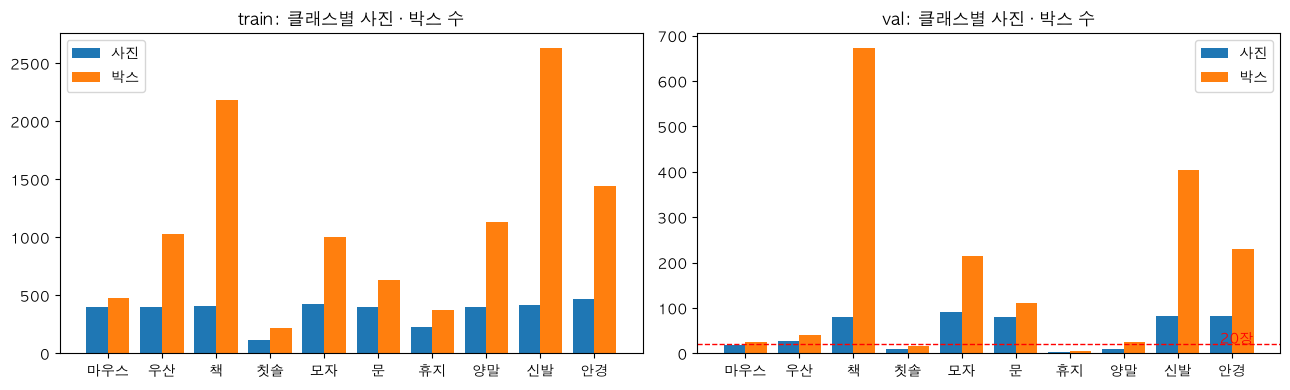

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, split in zip(axes, ['train', 'val']):
    part = summary[summary.split == split].set_index('cls').loc[ORDER]
    xs = np.arange(len(ORDER))
    ax.bar(xs - 0.2, part['images'], 0.4, label='사진')
    ax.bar(xs + 0.2, part['boxes'], 0.4, label='박스')
    ax.set_xticks(xs, [KO[k] for k in ORDER]); ax.set_title(f'{split}: 클래스별 사진 · 박스 수'); ax.legend()
axes[1].axhline(20, color='red', ls='--', lw=1); axes[1].text(9.4, 22, '20장', color='red', ha='right')
plt.tight_layout(); plt.show()

- 박스 수와 사진 수가 크게 차이 나는 클래스(사진당 박스가 많은)는 **한 사진에 여러 개가 같이 찍힌** 장면이다 — 앱 장면(물건 하나)과 다르다.
- val 사진이 아주 적은 클래스는 A · B의 클래스별 점수 자체를 조심해서 읽어야 한다 (몇 장만 틀려도 크게 바뀜).

## 2. 박스 크기

앱에서는 물건이 스캔 틀의 **긴 변 기준 40% 이상**을 차지해야 인정한다. 정사각형에 가까운 물건이면 틀 면적의 약 16%(0.4²) 이상이다.
반면 학습 박스가 사진 면적의 1%도 안 되면, 모델은 "멀리 있는 작은 물건"을 주로 배운 것이다.

- 빨간 점선: **1%** (실험 C에서 지우는 기준)
- 초록 점선: **16%** (앱에서 물건이 차지하는 대략의 최소 크기)
- 크기 차이가 커서 **로그 축**으로 그린다.

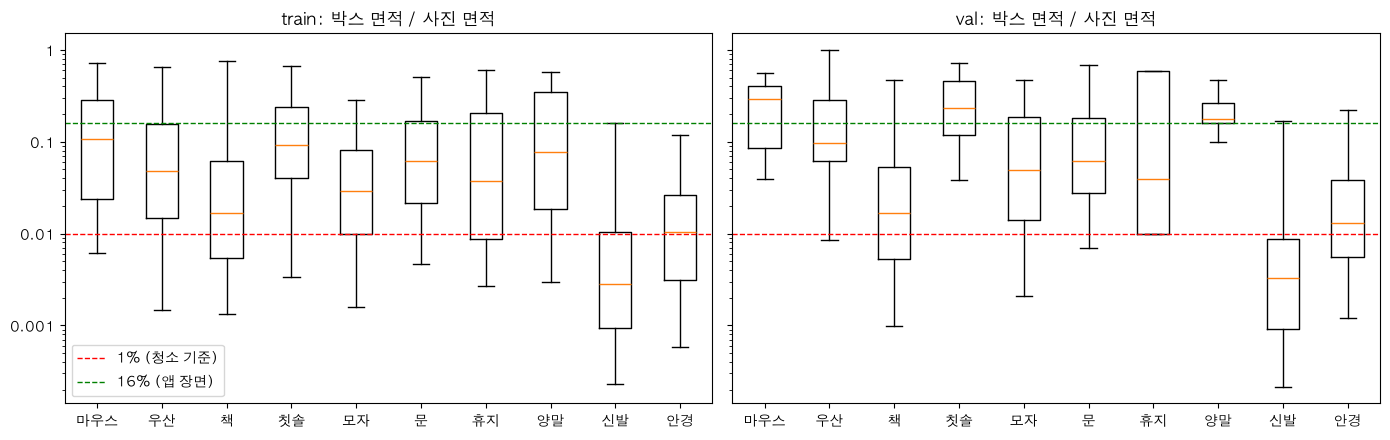

In [5]:
def class_boxplot(ax, df, col, title, log=True):
    """클래스별 col 분포를 상자 그림으로."""
    data = [df.loc[df.cls == k, col] for k in ORDER]
    ax.boxplot(data, showfliers=False, whis=(5, 95))     # 수염 = 5~95% (극단값은 숨김)
    ax.set_xticks(range(1, len(ORDER) + 1), [KO[k] for k in ORDER])
    if log:
        ax.set_yscale('log')
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))   # 10^-2 대신 0.01 (글꼴에 지수 기호가 없음)
        ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, split in zip(axes, ['train', 'val']):
    class_boxplot(ax, boxes[boxes.split == split], 'area', f'{split}: 박스 면적 / 사진 면적')
    ax.axhline(MIN_AREA, color='red', ls='--', lw=1, label='1% (청소 기준)')
    ax.axhline(0.16, color='green', ls='--', lw=1, label='16% (앱 장면)')
axes[0].legend(loc='lower left'); plt.tight_layout(); plt.show()

In [6]:
size = boxes.groupby(['cls', 'split'])['area'].agg(
    중앙값='median', 작음_pct=lambda a: 100 * (a < MIN_AREA).mean(), 앱크기_pct=lambda a: 100 * (a >= 0.16).mean())
size = size.unstack('split').loc[ORDER]
size.columns = [f'{s} {v}' for v, s in size.columns]
size.insert(0, '클래스', [KO[k] for k in size.index])
size.round(3)

,클래스,train 중앙값,val 중앙값,train 작음_pct,val 작음_pct,train 앱크기_pct,val 앱크기_pct
cls,,,,,,,
mouse,마우스,0.107,0.293,9.705,4.167,40.928,66.667
umbrella,우산,0.048,0.097,20.620,7.500,24.685,45.000
book,책,0.017,0.017,37.586,35.417,14.769,10.268
toothbrush,칫솔,0.092,0.233,11.416,0.000,38.356,62.500
hat,모자,0.029,0.049,25.200,18.140,13.500,29.302
door,문,0.061,0.062,12.954,8.108,27.330,29.730
toilet_paper,휴지,0.038,0.039,26.790,40.000,28.647,40.000
sock,양말,0.077,0.179,13.564,0.000,38.387,80.000
shoe,신발,0.003,0.003,74.353,75.248,5.023,5.941


- `작음_pct`: 면적 1% 미만 박스 비율, `앱크기_pct`: 16% 이상(앱처럼 크게 찍힌) 박스 비율.
- 신발 · 안경처럼 중앙값이 1% 근처거나 그 아래인 클래스는, **학습 박스 대부분이 앱 장면과 정반대**(아주 작음)다.

## 3. 사진당 박스 수

그 클래스가 있는 사진마다, 그 클래스 박스가 몇 개인지 센다. 책장(책 수십 권), 사람 무리(신발 여러 켤레) 같은 장면은 여기서 드러난다.

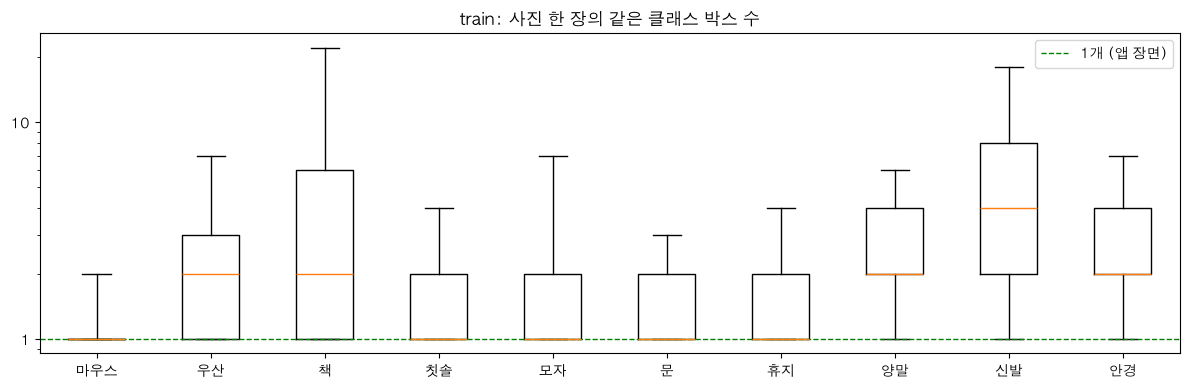

,클래스,평균,최대,한개_pct,다섯개이상_pct
cls,,,,,
mouse,마우스,1.2,8,86.8,1.0
umbrella,우산,2.6,18,43.3,13.6
book,책,5.4,88,43.0,29.6
toothbrush,칫솔,1.9,11,57.5,4.4
hat,모자,2.3,38,57.6,8.9
door,문,1.6,11,65.2,2.0
toilet_paper,휴지,1.7,19,63.3,3.1
sock,양말,2.8,30,17.5,6.5
shoe,신발,6.2,48,5.9,37.8


In [7]:
per_img = boxes.groupby(['split', 'cls', 'sample_id']).size().rename('n').reset_index()

fig, ax = plt.subplots(figsize=(12, 4))
class_boxplot(ax, per_img[per_img.split == 'train'], 'n', 'train: 사진 한 장의 같은 클래스 박스 수', log=True)
ax.axhline(1, color='green', ls='--', lw=1, label='1개 (앱 장면)'); ax.legend()
plt.tight_layout(); plt.show()

crowd = per_img[per_img.split == 'train'].groupby('cls')['n'].agg(
    평균='mean', 최대='max', 한개_pct=lambda n: 100 * (n == 1).mean(), 다섯개이상_pct=lambda n: 100 * (n >= 5).mean()).loc[ORDER]
crowd.insert(0, '클래스', [KO[k] for k in crowd.index])
crowd.round(1)

`한개_pct`가 낮을수록 "물건 하나만 찍힌 사진"이 드물다. 앱은 늘 한 개를 보여 주므로, 이런 클래스는 장면 차이가 크다.

## 4. 속성 (Open Images가 박스마다 달아 둔 표시)

| 속성 | 뜻 | 앱과의 관계 |
|---|---|---|
| `IsGroupOf` | 박스 하나가 **여러 개를 한꺼번에** 감쌈 (책장 = 책 박스 1개) | 앱엔 없음 → 지움 |
| `IsDepiction` | 진짜가 아니라 **그림 · 사진 · 인형** 속 물건 | 앱엔 없음 → 지움 |
| `IsOccluded` | 다른 물건에 **가려짐** | 앱에서도 손에 가릴 수 있음 → 남김 |
| `IsTruncated` | 사진 **가장자리에 잘림** | 남김 |
| `IsInside` | **건물 · 차 안에서** 찍음 (밖에서 본 것이 아님) | 정보만 |

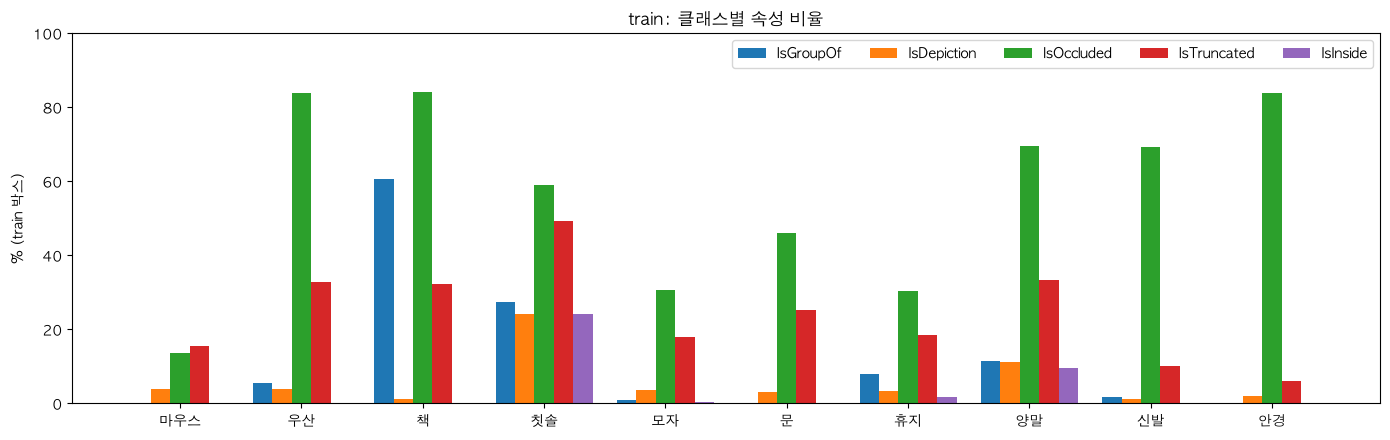

,클래스,IsGroupOf,IsDepiction,IsOccluded,IsTruncated,IsInside
cls,,,,,,
mouse,마우스,0.2,3.8,13.5,15.4,0.0
umbrella,우산,5.6,3.8,83.9,32.9,0.2
book,책,60.5,1.2,84.1,32.3,0.0
toothbrush,칫솔,27.4,24.2,58.9,49.3,24.2
hat,모자,0.9,3.7,30.7,18.0,0.3
door,문,0.2,3.0,46.0,25.1,0.2
toilet_paper,휴지,8.0,3.4,30.2,18.6,1.6
sock,양말,11.3,11.2,69.5,33.2,9.7
shoe,신발,1.8,1.3,69.3,10.2,0.1


In [8]:
ATTRS = ['IsGroupOf', 'IsDepiction', 'IsOccluded', 'IsTruncated', 'IsInside']
train = boxes[boxes.split == 'train']
attr = (100 * train.groupby('cls')[ATTRS].mean()).loc[ORDER]

fig, ax = plt.subplots(figsize=(14, 4.5))
xs, width = np.arange(len(ORDER)), 0.16
for i, a in enumerate(ATTRS):
    ax.bar(xs + (i - 2) * width, attr[a], width, label=a)
ax.set_xticks(xs, [KO[k] for k in ORDER]); ax.set_ylabel('% (train 박스)'); ax.set_ylim(0, 100)
ax.set_title('train: 클래스별 속성 비율'); ax.legend(ncol=5); plt.tight_layout(); plt.show()

attr.insert(0, '클래스', [KO[k] for k in attr.index])
attr.round(1)

- **책의 `IsGroupOf`** 가 다른 클래스보다 훨씬 높다 → 책 박스의 상당수가 "책 한 권"이 아니라 "책장 · 책 더미"다. 앱에서 책 한 권을 비추면, 모델이 배운 책과 모양이 다르다.
- `IsDepiction`(그림 속 물건)도 클래스마다 조금씩 있다. 가짜 물건으로 배울 이유는 없다.
- `IsOccluded` · `IsTruncated`는 많지만, 앱에서도 손에 가리거나 틀에 잘릴 수 있어 지우지 않는다.
- 그런데 **칫솔**은 묶음 · 그림 · 안쪽 비율이 모두 이상하게 높다. 칫솔 사진이 그렇게 특이할까? 아래에서 확인한다.

### 함정: 속성 "모름(-1)"이 True로 읽힌다

Open Images 원본 CSV(`detections.csv`)에서 속성값은 `1`(예) · `0`(아니오) · **`-1`(확인 안 함)** 이다.
FiftyOne은 이 값을 bool로 바꾸는데, 파이썬에서 `bool(-1)`은 `True`다 → **"모름"이 다섯 속성 모두 True**로 들어온다.

실제로 다섯 속성이 **모두** True인 박스(묶음이면서 그림이면서 건물 안 …)는 진짜로는 거의 있을 수 없다. 이런 박스를 `attr_unknown`으로 표시했다.

In [9]:
unknown = train.groupby('cls').agg(박스=('attr_unknown', 'size'), 모름=('attr_unknown', 'sum')).loc[ORDER]
unknown['모름%'] = 100 * unknown['모름'] / unknown['박스']
# 모름 때문에'만' 지워지는 박스: 모름이고, 면적 기준으로는 남았을 박스
only_unknown = train[train.attr_unknown & (train.area >= MIN_AREA)]
unknown['모름 때문에만 지움'] = only_unknown.groupby('cls').size().reindex(ORDER, fill_value=0)
unknown.insert(0, '클래스', [KO[k] for k in unknown.index])
print('val 모름 박스:', int(boxes.loc[boxes.split == 'val', 'attr_unknown'].sum()))
unknown.round(1)

val 모름 박스: 0


,클래스,박스,모름,모름%,모름 때문에만 지움
cls,,,,,
mouse,마우스,474,0,0.0,0
umbrella,우산,1033,2,0.2,2
book,책,2187,1,0.0,1
toothbrush,칫솔,219,53,24.2,49
hat,모자,1000,3,0.3,3
door,문,633,1,0.2,1
toilet_paper,휴지,377,6,1.6,6
sock,양말,1128,109,9.7,98
shoe,신발,2628,0,0.0,0


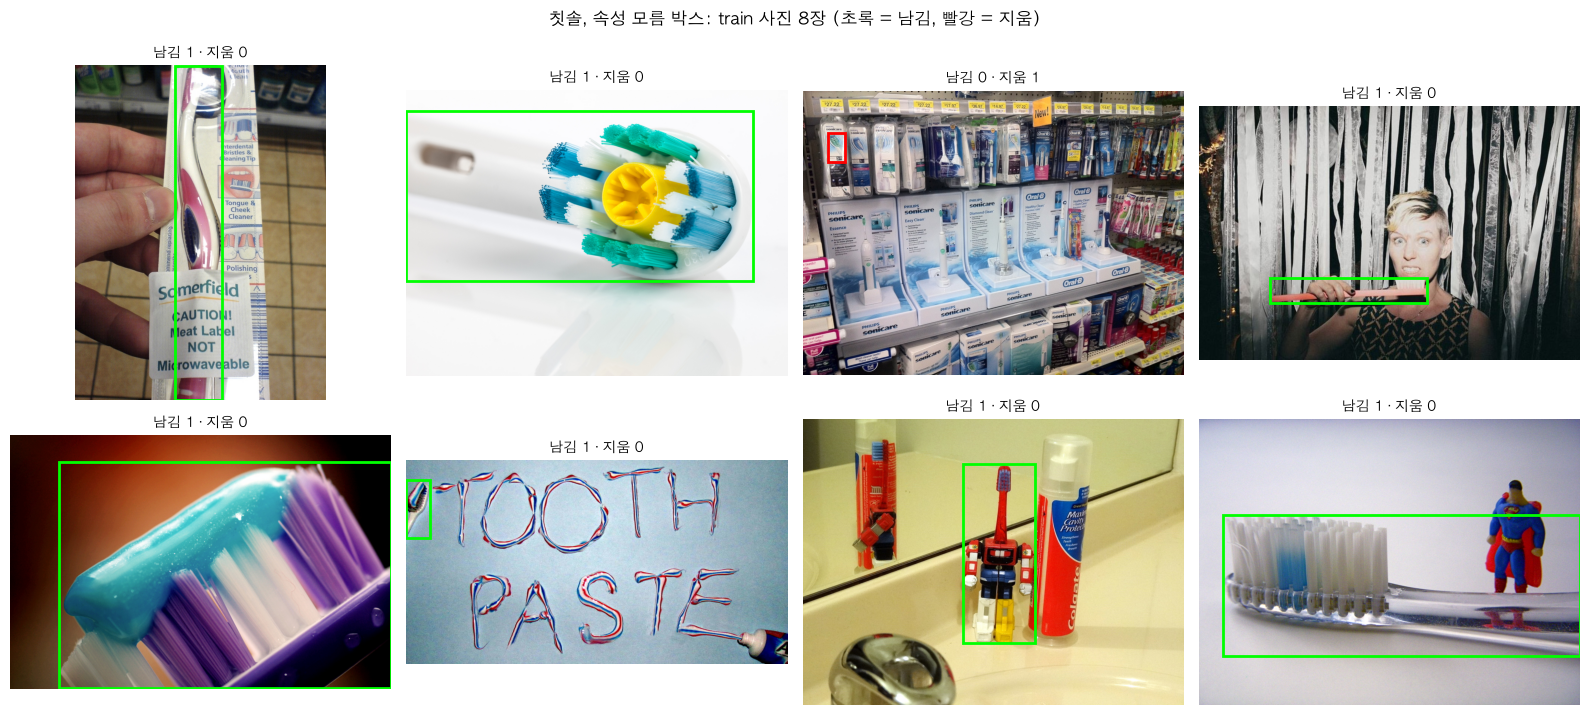

In [10]:
def show_gallery(part, title, n=8, seed=SEED):
    """part(박스 표 일부)에 있는 사진 n장을 무작위로 골라 그 박스들을 그린다 (초록 = 남김, 빨강 = 지움)."""
    ids = pd.Series(part.sample_id.unique()).sample(min(n, part.sample_id.nunique()), random_state=seed)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
    for ax in axes.flat:
        ax.axis('off')
    for ax, sid in zip(axes.flat, ids):
        rows = part[part.sample_id == sid]
        img = Image.open(rows.filepath.iloc[0]).convert('RGB')
        W, H = img.size
        ax.imshow(img)
        for r in rows.itertuples():
            color = 'red' if r.drop else 'lime'
            ax.add_patch(Rectangle((r.x * W, r.y * H), r.w * W, r.h * H, fill=False, ec=color, lw=2))
        ax.set_title(f'남김 {(~rows["drop"]).sum()} · 지움 {rows["drop"].sum()}', fontsize=10)
    fig.suptitle(f'{title}: train 사진 {len(ids)}장 (초록 = 남김, 빨강 = 지움)')
    plt.tight_layout(); plt.show()

show_gallery(train[train.attr_unknown & (train.cls == 'toothbrush')], '칫솔, 속성 모름 박스')

- 칫솔 · 양말의 높은 묶음% · 그림%는 **대부분 이 "모름" 박스** 때문이다. 위 사진처럼 칫솔 하나를 크게 찍은 평범한 사진이 많다 — 묶음도 그림도 아니다.
- 그래서 실험 C의 청소 규칙(`src/clean.py`의 `should_drop`)은 다섯 속성이 모두 True인 박스를 **"모름"으로 보고 면적 규칙만** 적용한다. (이걸 모르고 지웠다면 앱 장면과 가장 닮은 칫솔 · 양말 사진을 잃었을 것)
- val에는 이런 박스가 거의 없다(위 출력) → train과 val의 속성 분포가 다르다는 것도 기억해 둔다.
- 고치려면: 다섯 속성이 모두 True인 박스는 "모름"으로 보고 면적 기준만 적용한다 (이 노트북은 실험 C와 같은 규칙으로 `drop`을 계산하고, 고친 규칙은 다음 실험 몫으로 남긴다).

## 5. 위치 히트맵 — 물건이 가운데에 있나?

앱에서는 물건이 **항상 가운데**에 온다. 학습 사진의 박스 중심(`cx, cy`)을 10×10 칸으로 세어 본다 (밝을수록 많음, 클래스마다 따로 정규화).

"가운데"는 사진을 3×3으로 나눈 **한가운데 칸**에 중심이 있는 박스로 정한다. 중심이 아무 데나 고르게 있으면 약 11%(1/9)가 나온다.

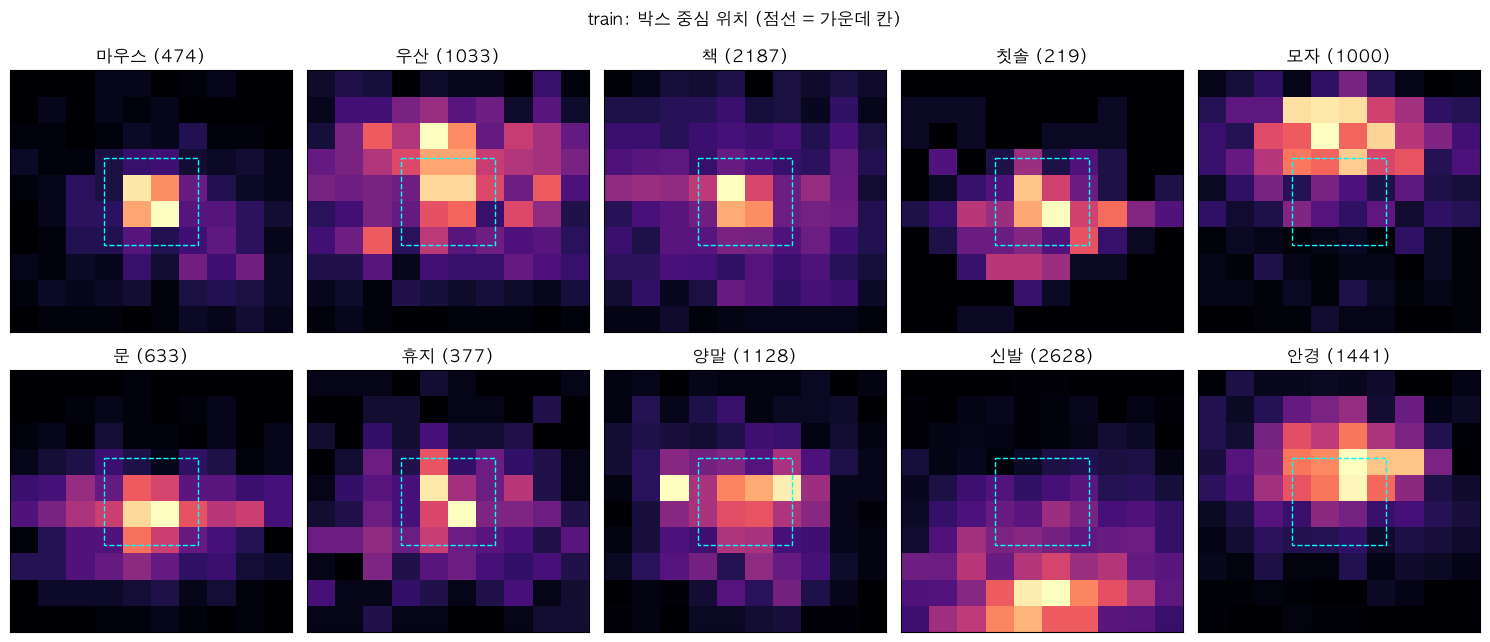

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, k in zip(axes.flat, ORDER):
    part = train[train.cls == k]
    ax.hist2d(part.cx, part.cy, bins=10, range=[[0, 1], [0, 1]], cmap='magma', density=True)
    ax.add_patch(Rectangle((1/3, 1/3), 1/3, 1/3, fill=False, ec='cyan', lw=1, ls='--'))
    ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])     # 사진처럼 위가 y=0
    ax.set_title(f'{KO[k]} ({len(part)})')
fig.suptitle('train: 박스 중심 위치 (점선 = 가운데 칸)'); plt.tight_layout(); plt.show()

In [12]:
def centered_pct(df):
    """박스 중심이 3×3 한가운데 칸에 있는 비율(%)."""
    mid = df.cx.between(1/3, 2/3) & df.cy.between(1/3, 2/3)
    return 100 * mid.mean()

center = pd.DataFrame({'클래스': [KO[k] for k in ORDER],
                       '가운데_pct': [centered_pct(train[train.cls == k]) for k in ORDER],
                       '중심 y 중앙값': [train.loc[train.cls == k, 'cy'].median() for k in ORDER]}, index=ORDER)
center.round(2)

,클래스,가운데_pct,중심 y 중앙값
mouse,마우스,43.25,0.53
umbrella,우산,23.62,0.42
book,책,23.96,0.50
toothbrush,칫솔,45.21,0.53
hat,모자,14.00,0.29
door,문,37.28,0.56
toilet_paper,휴지,33.69,0.54
sock,양말,31.56,0.50
shoe,신발,11.83,0.77
glasses,안경,31.16,0.37


- 대부분 고르게 퍼졌을 때(11%)보다는 가운데가 많지만, 앱처럼 "항상 가운데"와는 거리가 멀다. 모자 · 신발은 거의 고르게 퍼진 수준이다.
- 신발은 중심이 사진 **아래쪽**(`중심 y`가 큼)에 몰린다 — 사람 전신 사진의 발끝이다. 모자 · 안경은 위쪽(머리)에 몰린다.
- YOLO는 합성곱이라 위치에 꽤 둔감하고 모자이크 증강이 위치를 섞어 주므로, 위치 자체보다는 **"사람 전신 사진의 일부"라는 장면**이 문제다.

## 6. 가로세로 비율

`aspect` = 픽셀 기준 가로/세로. 1이면 정사각형, 1보다 작으면 세로로 길고, 크면 가로로 길다 (로그 축).

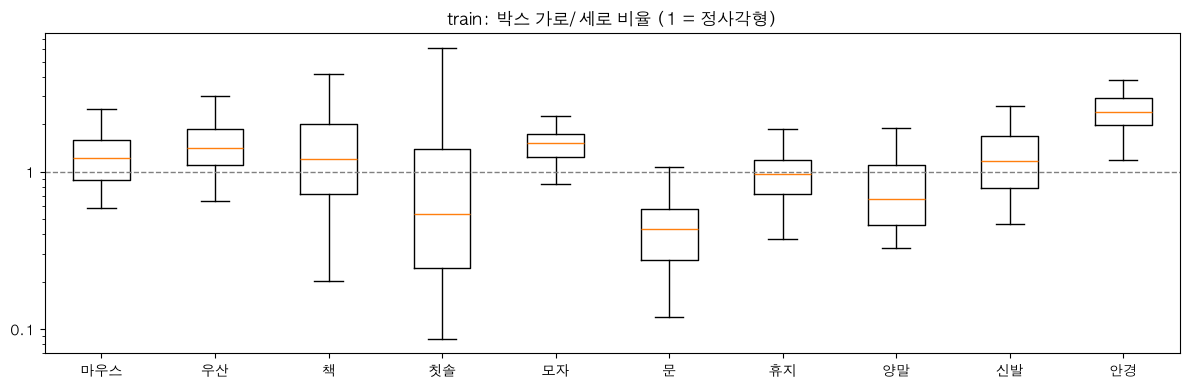

,클래스,중앙값,하위10,상위90
cls,,,,
mouse,마우스,1.21,0.65,2.19
umbrella,우산,1.41,0.87,2.44
book,책,1.19,0.41,3.15
toothbrush,칫솔,0.54,0.10,2.93
hat,모자,1.51,1.00,2.02
door,문,0.43,0.15,0.85
toilet_paper,휴지,0.96,0.52,1.54
sock,양말,0.67,0.36,1.60
shoe,신발,1.16,0.56,2.25


In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
class_boxplot(ax, train, 'aspect', 'train: 박스 가로/세로 비율 (1 = 정사각형)')
ax.axhline(1, color='gray', ls='--', lw=1); plt.tight_layout(); plt.show()

shape = train.groupby('cls')['aspect'].agg(중앙값='median', 하위10=lambda a: a.quantile(0.1),
                                           상위90=lambda a: a.quantile(0.9)).loc[ORDER]
shape.insert(0, '클래스', [KO[k] for k in shape.index])
shape.round(2)

- **문은 세로로 길고**, **안경은 가로로 길고**, **칫솔은 가늘고 길다**.
- 가늘고 긴 물건은 틀 안에 크게 들어와도 **면적은 작다** (칫솔이 틀 긴 변의 80%를 채워도 폭이 좁으면 면적은 10%도 안 될 수 있음).
- 그래서 웹앱은 "주인공 박스"를 **면적이 아니라 긴 변**(틀 한 변의 40% 이상)으로 고른다. 면적 기준이면 칫솔 · 안경이 억울하게 떨어진다.

## 7. 같이 나오는 클래스

칸 = 두 클래스가 **같은 사진에 함께 있는 사진 수** (대각선 = 그 클래스가 있는 사진 수).
오른쪽은 행 기준 비율: "행 클래스가 있는 사진 중 열 클래스도 있는 비율(%)".
양말 사진에 신발이 자주 같이 있으면, 모델은 양말 · 신발을 **함께 보며** 배워서 둘을 헷갈리기 쉽다.

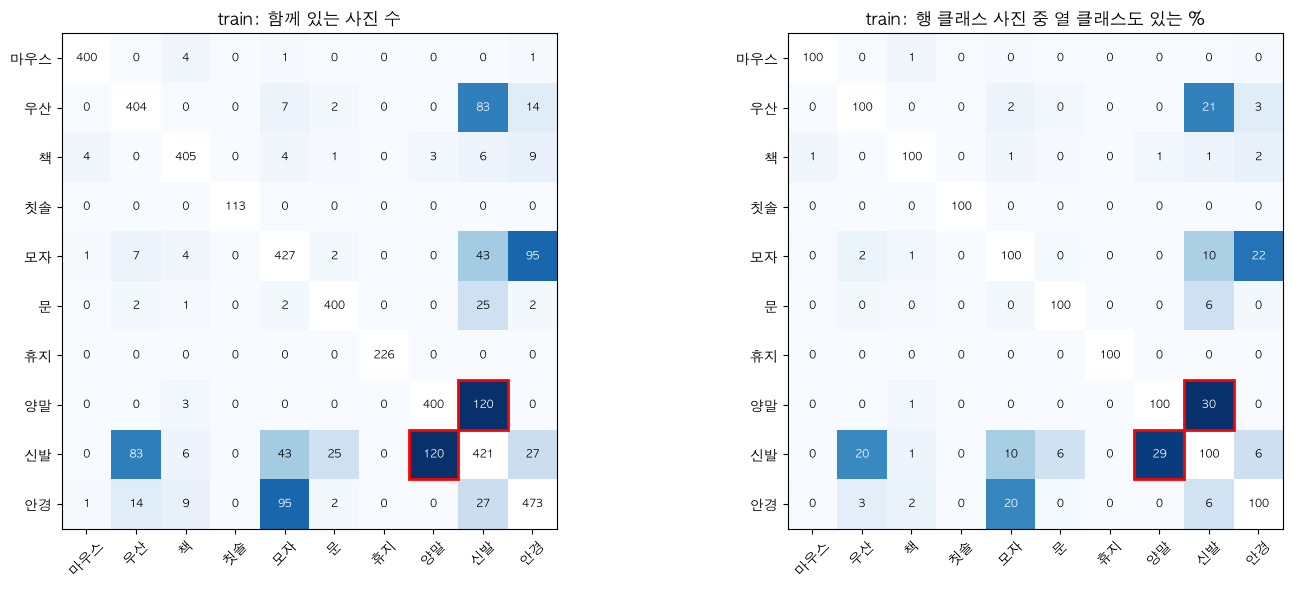

양말 사진 400장 중 신발도 있음: 120장 (30%)
신발 사진 421장 중 양말도 있음: 120장 (29%)


In [14]:
co = EDA.cooccurrence(train)
co_pct = 100 * co.div(np.diag(co), axis=0)            # 행 클래스 사진 중 % (대각선 = 100)
labels = [KO[k] for k in ORDER]
i_sock, i_shoe = ORDER.index('sock'), ORDER.index('shoe')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, m, title, fmt in [(axes[0], co, '함께 있는 사진 수', '{:.0f}'), (axes[1], co_pct, '행 클래스 사진 중 열 클래스도 있는 %', '{:.0f}')]:
    shown = m.values.astype(float).copy(); np.fill_diagonal(shown, np.nan)   # 대각선은 색에서 뺌
    ax.imshow(shown, cmap='Blues')
    ax.set_xticks(range(10), labels, rotation=45); ax.set_yticks(range(10), labels); ax.set_title(f'train: {title}')
    dark = 0.6 * np.nanmax(shown)                                         # 진한 칸은 흰 글씨
    for r in range(10):
        for c in range(10):
            color = 'white' if r != c and shown[r, c] > dark else 'black'
            ax.text(c, r, fmt.format(m.values[r, c]), ha='center', va='center', fontsize=8, color=color)
    for r, c in [(i_sock, i_shoe), (i_shoe, i_sock)]:                      # 양말 ↔ 신발 강조
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec='red', lw=2))
plt.tight_layout(); plt.show()
print(f"양말 사진 {co.loc['sock', 'sock']}장 중 신발도 있음: {co.loc['sock', 'shoe']}장 ({co_pct.loc['sock', 'shoe']:.0f}%)")
print(f"신발 사진 {co.loc['shoe', 'shoe']}장 중 양말도 있음: {co.loc['shoe', 'sock']}장 ({co_pct.loc['shoe', 'sock']:.0f}%)")

- **양말 → 신발**: 양말 사진의 상당수에 신발이 같이 있다 (발 사진). 양말은 신발 속이나 옆에 있어 경계가 애매하다 → 혼동행렬에서 양말↔신발을 집중해서 본 이유.
- 다른 큰 칸(예: 모자 ↔ 안경, 우산 ↔ 신발)은 **사람이 찍힌 사진**이라는 공통점이다. 사람 전신 · 얼굴 사진이 많다는 뜻.
- 이 숫자는 **최소값**이다. Open Images는 사진마다 확인한 클래스만 박스를 그려서(빠진 라벨), 실제로는 같이 있어도 0으로 세어질 수 있다.

## 8. 사진 해상도

Open Images 사진은 대부분 긴 변이 1024픽셀로 줄어 있다. 학습은 640, 웹앱은 320으로 줄여 넣으므로,
작은 박스(1% 미만)는 320 입력에서 **몇 픽셀**밖에 안 된다.

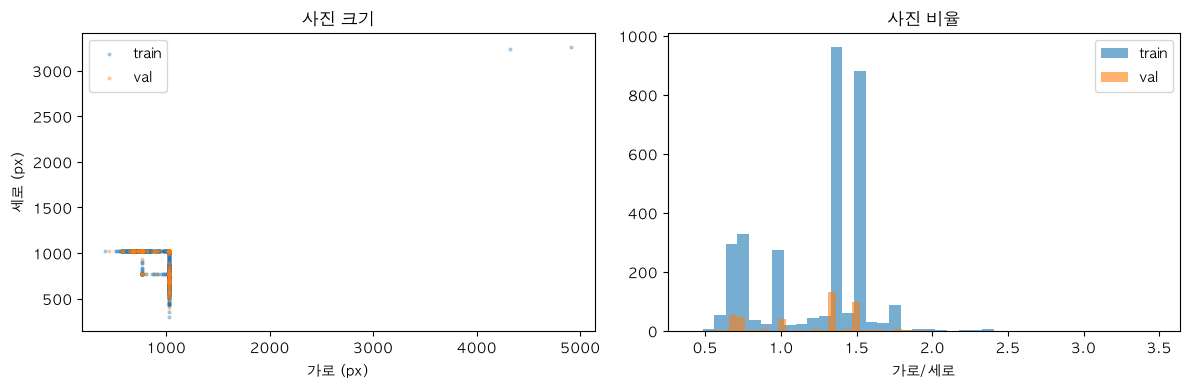

        img_w  img_h
split               
train  1024.0  768.0
val    1024.0  768.0
면적 1% 정사각형 박스 = 320 입력에서 약 32×32 픽셀


In [15]:
imgs = boxes.drop_duplicates('sample_id')[['split', 'img_w', 'img_h']]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split, color in [('train', 'tab:blue'), ('val', 'tab:orange')]:
    part = imgs[imgs.split == split]
    axes[0].scatter(part.img_w, part.img_h, s=4, alpha=0.3, color=color, label=split)
    axes[1].hist(part.img_w / part.img_h, bins=40, alpha=0.6, color=color, label=split)
axes[0].set_xlabel('가로 (px)'); axes[0].set_ylabel('세로 (px)'); axes[0].set_title('사진 크기'); axes[0].legend()
axes[1].set_xlabel('가로/세로'); axes[1].set_title('사진 비율'); axes[1].legend()
plt.tight_layout(); plt.show()

side = np.sqrt(MIN_AREA) * 320
print(imgs.groupby('split')[['img_w', 'img_h']].median())
print(f'면적 1% 정사각형 박스 = 320 입력에서 약 {side:.0f}×{side:.0f} 픽셀')

## 9. 클래스별 사진 모아 보기 — 문 · 책 · 신발

숫자만으로는 감이 안 온다. 점수가 가장 낮은 세 클래스의 train 사진을 무작위로 8장씩 본다 (`show_gallery`는 4절에서 만든 함수).

- **초록** 박스: 청소 후에도 남는 박스
- **빨강** 박스: 청소 규칙(묶음 · 그림 · 1% 미만)에 걸려 지워질 박스

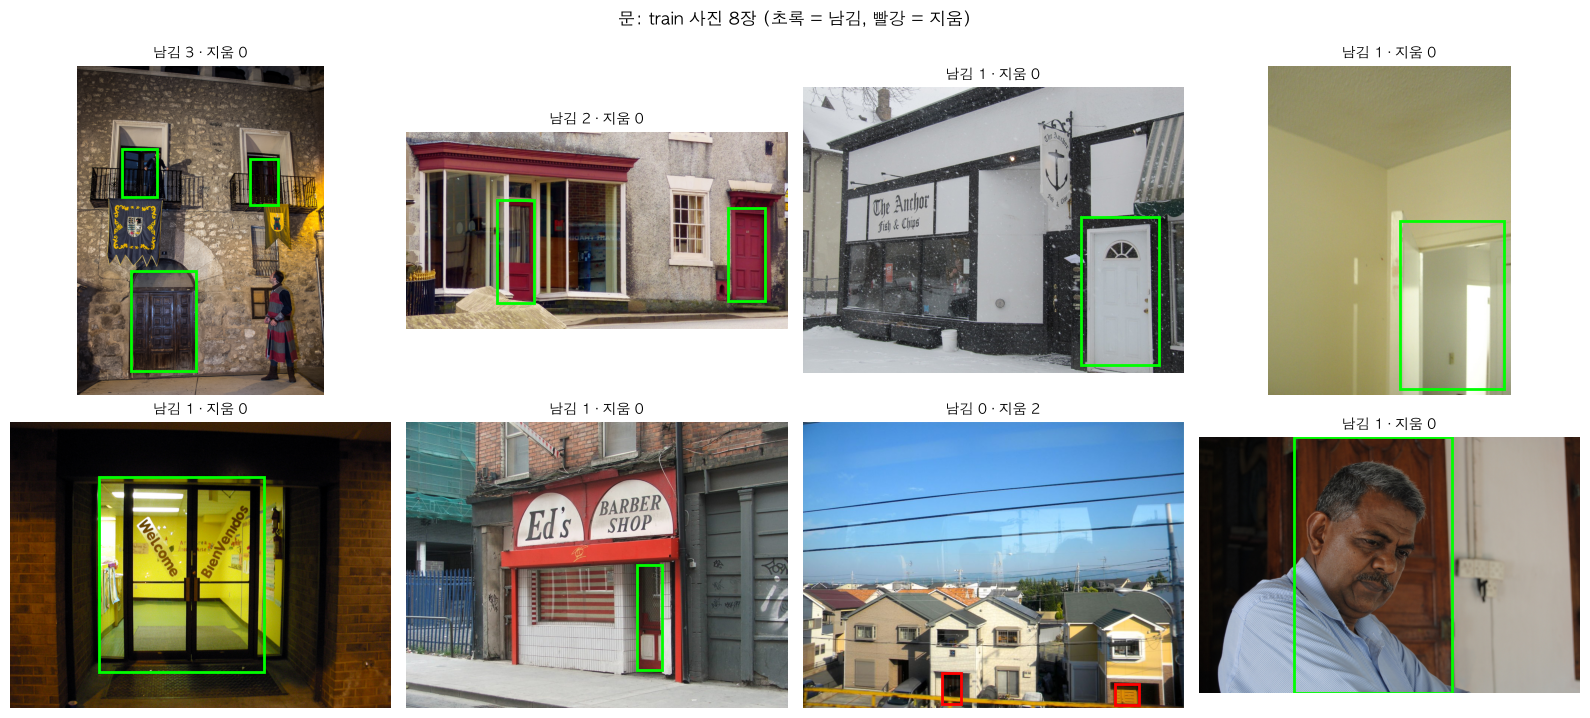

In [16]:
show_gallery(train[train.cls == 'door'], '문')

**문**: 건물 외벽 · 거리 사진 속 문이 많다. 이런 박스는 묶음도 아니고 아주 작지도 않아서 **대부분 초록(남김)** 이다.
앱에서는 방문 앞에 서서 문 하나를 비추는데, 학습 사진의 문은 건물 정면의 일부다 → **청소 규칙으로는 이 차이가 안 지워진다.**

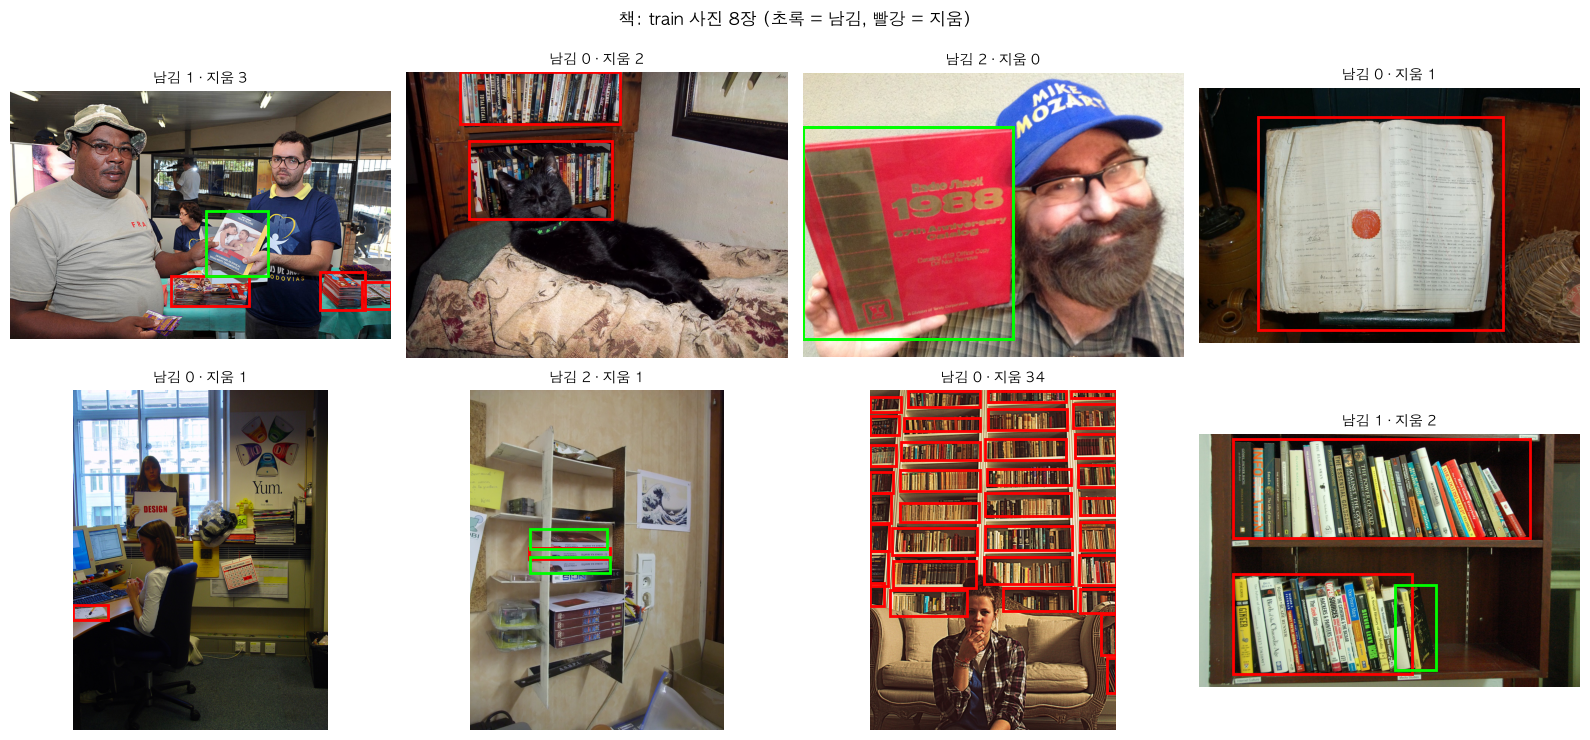

In [17]:
show_gallery(train[train.cls == 'book'], '책')

**책**: 책장 · 책 더미를 통째로 감싼 묶음 박스(빨강)가 눈에 띈다. 같은 사진의 작은 책 박스들도 빨강이다.

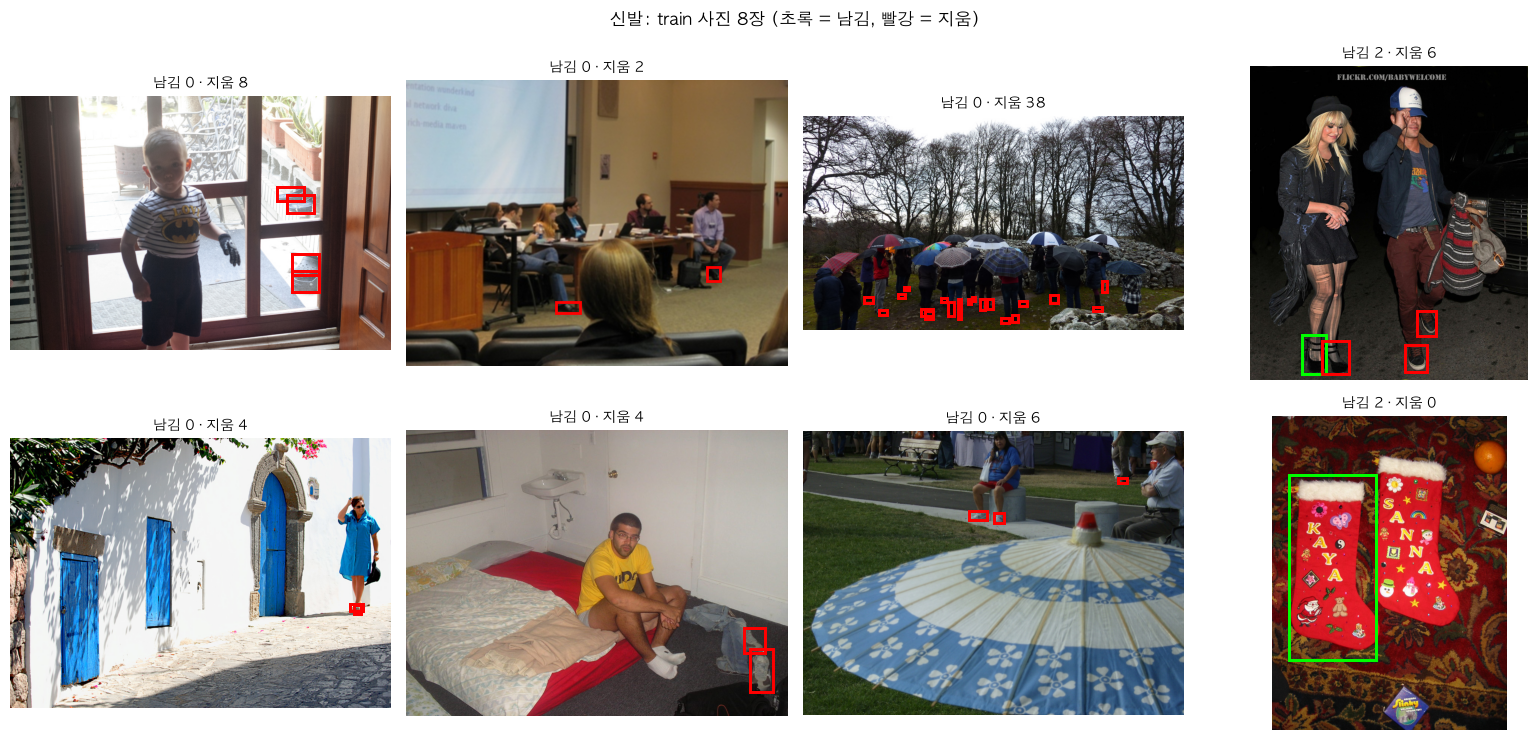

In [18]:
show_gallery(train[train.cls == 'shoe'], '신발')

**신발**: 사람 전신 사진의 발끝 — 작은 빨강 박스가 대부분이다. 앱처럼 신발 한 짝을 크게 찍은 사진은 드물다.

## 10. 발견 정리 → 청소 규칙

먼저 위에서 본 숫자를 클래스별로 한 표에 모은다 (train 기준). 실험 A의 mAP50(위 소개 표)과 나란히 놓고 본다.

In [19]:
A_MAP50 = dict(mouse=.87, toothbrush=.85, toilet_paper=.82, glasses=.75, hat=.71,
               umbrella=.70, sock=.51, shoe=.42, door=.36, book=.33)   # 실험 A 결과 (wakeup_mission.ipynb)

found = pd.DataFrame({
    '클래스': [KO[k] for k in ORDER],
    'A mAP50': [A_MAP50[k] for k in ORDER],
    '면적 중앙값': size['train 중앙값'],
    '사진당 박스': table['train boxes_per_image'],
    '묶음%': attr['IsGroupOf'],
    '그림%': attr['IsDepiction'],
    '작음%': size['train 작음_pct'],
    '모름%': unknown['모름%'],
    '지움%': 100 * train.groupby('cls')['drop'].mean().loc[ORDER],
    '가운데%': center['가운데_pct'],
    'val 사진': table['val images'],
}, index=ORDER)
found.sort_values('A mAP50').round(3)

,클래스,A mAP50,면적 중앙값,사진당 박스,묶음%,그림%,작음%,모름%,지움%,가운데%,val 사진
book,책,0.33,0.017,5.400,60.540,1.235,37.586,0.046,75.492,23.960,80.0
door,문,0.36,0.061,1.582,0.158,3.002,12.954,0.158,15.324,37.283,80.0
shoe,신발,0.42,0.003,6.242,1.788,1.294,74.353,0.000,74.924,11.834,82.0
sock,양말,0.51,0.077,2.820,11.348,11.170,13.564,9.663,16.046,31.560,10.0
umbrella,우산,0.70,0.048,2.557,5.615,3.775,20.620,0.194,28.848,23.621,27.0
hat,모자,0.71,0.029,2.342,0.900,3.700,25.200,0.300,29.000,14.000,91.0
glasses,안경,0.75,0.010,3.047,0.139,2.082,48.716,0.139,50.104,31.159,83.0
toilet_paper,휴지,0.82,0.038,1.668,7.958,3.448,26.790,1.592,33.952,33.687,4.0
toothbrush,칫솔,0.85,0.092,1.938,27.397,24.201,11.416,24.201,14.612,45.205,10.0
mouse,마우스,0.87,0.107,1.185,0.211,3.797,9.705,0.000,13.713,43.249,19.0


In [20]:
print('A mAP50과의 순위 상관 (Spearman, 10개 클래스라 참고만):')
for col in ['면적 중앙값', '사진당 박스', '묶음%', '작음%', '지움%', '가운데%']:
    print(f'  {col:8s} {found["A mAP50"].corr(found[col], method="spearman"):+.2f}')

A mAP50과의 순위 상관 (Spearman, 10개 클래스라 참고만):
  면적 중앙값   +0.47
  사진당 박스   -0.55
  묶음%      -0.16
  작음%      -0.42
  지움%      -0.52
  가운데%     +0.52


상관 숫자는 클래스 10개뿐이라 **방향만** 본다 (부호가 + 면 그 값이 클수록 점수가 높았다는 뜻).

- 박스가 크고 · 가운데에 있고 · 사진당 박스가 적은 클래스일수록 점수가 높은 쪽이다 → "앱 장면과 닮은 데이터일수록 잘 배운다"는 가설과 같은 방향.
- 반면 `지움%` 하나만으로는 점수를 잘 설명하지 못한다. 안경은 절반을 지울 만큼 작은 박스가 많은데도 점수가 높고, 문은 지울 게 적은데도 낮다.
  → 청소는 **일부 클래스(책 · 신발)** 에 대한 처방이지, 모든 클래스의 답은 아니다.

### 발견 → 결정

숫자는 바로 위 표(전체 데이터 기준)에서 읽는다. 아래 괄호 속 숫자는 **전체 데이터(train 클래스당 400장) 기준**으로 미리 확인한 값이다.

| 발견 | 결정 (실험 C · 웹앱) |
|---|---|
| 책 박스의 상당수가 책장 · 더미를 감싼 **묶음 박스** (책 묶음 약 61%) | `IsGroupOf` 박스는 지운다 |
| 신발 · 안경 박스 다수가 사진 면적 **1% 미만** (신발 약 74%, 안경 약 49%) | 면적 1% 미만 박스는 지운다 |
| 그림 · 사진 속 물건(`IsDepiction`)이 섞여 있음 | 지운다 |
| 라벨만 지우면 그 자리의 물건을 "배경"으로 배움 (빠진 라벨 함정) | 지운 박스 자리를 **회색(114)으로 칠한다** (남긴 박스 안은 그대로) |
| 가려짐 · 잘림은 많지만 앱에서도 생길 수 있음 | 남긴다 |
| **문**은 지울 박스가 적은데도 점수가 낮음 — 건물 외벽 속 문 (문 지움 약 15%) | 청소로는 크게 안 나아질 것으로 **예측**. 나중에 앱 장면에 가까운 문 사진을 더 모아야 함 |
| 문 · 칫솔 · 안경은 가로세로 비율이 극단적 | 웹앱 주인공 박스는 **면적이 아니라 긴 변** 기준 |
| 양말 사진에 신발이 자주 같이 있음 | 혼동행렬에서 양말↔신발을 따로 본다 |
| 속성 "모름(-1)"이 FiftyOne에서 모두 True로 읽힘 — 칫솔 · 양말에 몰림 (칫솔 약 24%, 양말 약 10%) | 실험 C는 이 박스도 지운다 (C의 알려진 한계). 다음 청소에서는 "모름"이면 면적 기준만 적용 |
| 휴지 · 칫솔 · 양말 · 마우스의 **val 사진이 20장 미만** (휴지 4장, 양말 · 칫솔 10장, 마우스 19장) | 이 클래스들의 val 점수는 조심해서 읽고, 앱 기준 통과율 · 직접 찍은 사진으로 함께 판단 |

## 11. 청소 후 다시 보기 (전/후)

`drop == False`인 박스만 남기면 데이터가 어떻게 바뀌나? (이 표만으로 계산한다. 실제 이미지를 칠하지는 않는다.)

실험 C의 **실제 학습 데이터**(회색 칠한 사진 + 라벨, `data/yolo_clean`)는 `wakeup_clean.ipynb`가 만든다.
그쪽은 겹친 박스 제거까지 하므로 박스 수가 여기보다 조금 적다.

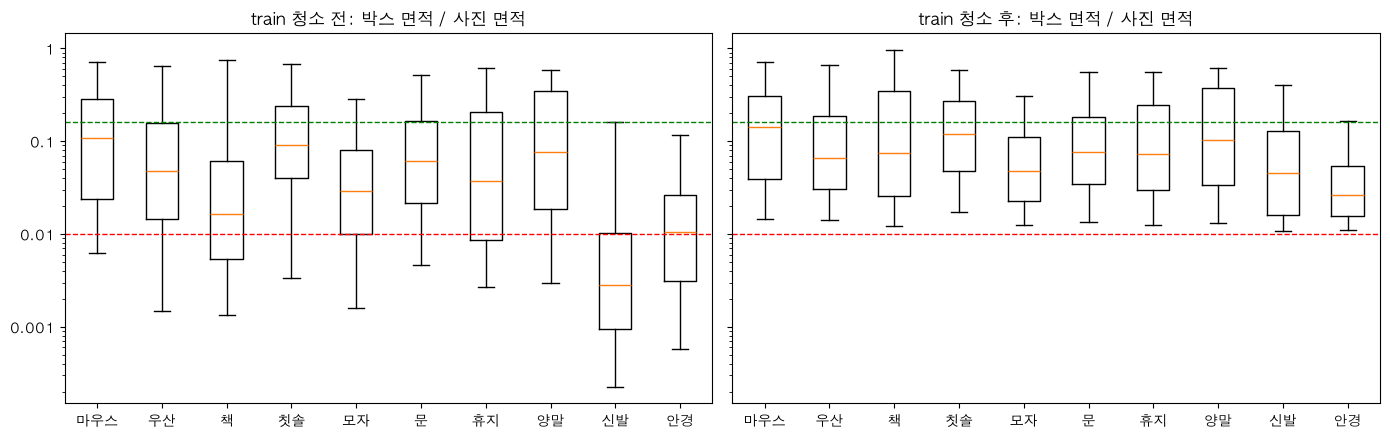

In [21]:
kept = boxes[~boxes['drop']]
stages = {'전': boxes[boxes.split == 'train'], '후': kept[kept.split == 'train']}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (name, df) in zip(axes, stages.items()):
    class_boxplot(ax, df, 'area', f'train 청소 {name}: 박스 면적 / 사진 면적')
    ax.axhline(MIN_AREA, color='red', ls='--', lw=1); ax.axhline(0.16, color='green', ls='--', lw=1)
plt.tight_layout(); plt.show()

In [22]:
before_after = pd.DataFrame(index=ORDER)
before_after['클래스'] = [KO[k] for k in ORDER]
for name, df in stages.items():
    s = EDA.class_summary(df).set_index('cls').loc[ORDER]
    before_after[f'박스 {name}'] = s['boxes']
    before_after[f'사진 {name}'] = s['images']
    before_after[f'사진당 박스 {name}'] = s['boxes_per_image'].round(2)
    before_after[f'면적 중앙값 {name}'] = df.groupby('cls')['area'].median().reindex(ORDER).round(3)
before_after['남김%'] = (100 * before_after['박스 후'] / before_after['박스 전']).round(1)

# 박스가 모두 지워진 사진 = 청소 후 빈 라벨(배경) 사진
all_dropped = boxes[boxes.split == 'train'].groupby('sample_id')['drop'].all()
print('train 사진 중 박스가 모두 지워지는 사진:', all_dropped.sum(), '/', len(all_dropped))
before_after

train 사진 중 박스가 모두 지워지는 사진: 579 / 3237


,클래스,박스 전,사진 전,사진당 박스 전,면적 중앙값 전,박스 후,사진 후,사진당 박스 후,면적 중앙값 후,남김%
mouse,마우스,474,400,1.18,0.107,409,346,1.18,0.142,86.3
umbrella,우산,1033,404,2.56,0.048,735,352,2.09,0.067,71.2
book,책,2187,405,5.40,0.017,536,249,2.15,0.075,24.5
toothbrush,칫솔,219,113,1.94,0.092,187,105,1.78,0.119,85.4
hat,모자,1000,427,2.34,0.029,710,394,1.80,0.048,71.0
door,문,633,400,1.58,0.061,536,371,1.44,0.077,84.7
toilet_paper,휴지,377,226,1.67,0.038,249,164,1.52,0.072,66.0
sock,양말,1128,400,2.82,0.077,947,363,2.61,0.103,84.0
shoe,신발,2628,421,6.24,0.003,659,190,3.47,0.046,25.1
glasses,안경,1441,473,3.05,0.010,719,349,2.06,0.026,49.9


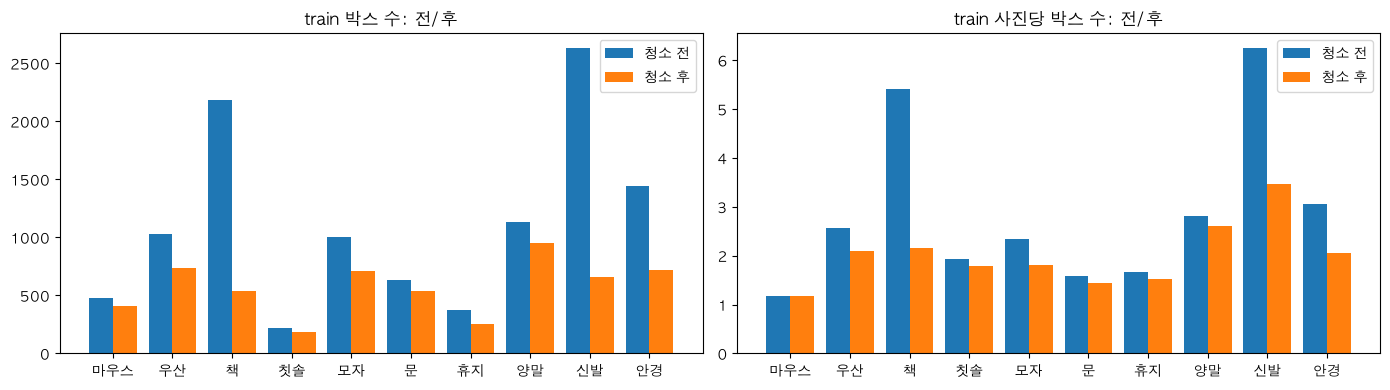

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
xs = np.arange(len(ORDER))
for ax, col, title in [(axes[0], '박스', 'train 박스 수'), (axes[1], '사진당 박스', 'train 사진당 박스 수')]:
    ax.bar(xs - 0.2, before_after[f'{col} 전'], 0.4, label='청소 전')
    ax.bar(xs + 0.2, before_after[f'{col} 후'], 0.4, label='청소 후')
    ax.set_xticks(xs, before_after['클래스']); ax.set_title(f'{title}: 전/후'); ax.legend()
plt.tight_layout(); plt.show()

### 정리

- 청소 후 박스 면적 분포가 위로 올라가고(작은 박스가 빠짐), 대부분의 클래스에서 사진당 박스 수가 1에 가까워진다 → **앱 장면에 더 가까운 데이터**.
  (칫솔은 예외: "모름" 박스가 많은 한 개짜리 사진이 통째로 빠져서 오히려 늘 수 있다.)
- 박스가 모두 지워진 사진은 실험 C에서 **회색 칠 + 빈 라벨**(배경 사진)이 된다. 위 출력처럼 그 수가 적지 않다.
- 대신 책 · 신발은 남는 박스가 크게 줄어든다. "앱과 닮은 적은 데이터"가 "앱과 다른 많은 데이터"보다 나은지가 실험 C의 질문이다.
- 문은 거의 그대로 남는다 → 실험 C에서 문 점수가 안 오른다면, 문 문제는 **장면(건물 외벽)** 때문이고 사진을 새로 모아야 한다는 증거다.
- 다음: `wakeup_clean.ipynb` (실험 C 학습 · 평가).